## Predicting Whether a Used Vehicle Sells on Schedule by comparing three classification Algorithms

### Objective
The objective is to compare classification models that predict whether a used vehicle sells on schedule. The target `ON_SCHEDULE` is created from `SELLING_PRICE`, `LISTING_DAYS`, and `BODY_TYPE`. Columns used to create the target will not be used as predictors.

## 1. Exploratory Data Analysis (EDA)

Reviewing the dataset structure, missing values, body types, and the target-class distribution. The EDA is kept focused on information needed for this classification task.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("used_vehicle_data.csv")

print("Dataset shape:", df.shape)
print("\nMissing values in target-related columns:")
print(df[["SELLING_PRICE", "LISTING_DAYS", "BODY_TYPE"]].isna().sum())
print("\nBody-type values:")
print(df["BODY_TYPE"].value_counts(dropna=False))

Dataset shape: (1815, 18)

Missing values in target-related columns:
SELLING_PRICE    10
LISTING_DAYS     18
BODY_TYPE        18
dtype: int64

Body-type values:
BODY_TYPE
SUV          579
Sedan        500
Truck        271
Hatchback    160
Coupe        125
Minivan      100
Wagon         62
NaN           18
Name: count, dtype: int64


## 2. Data Cleaning and Preparation

Categorical text values are standardized by trimming surrounding spaces and converting text to lowercase. Numeric columns are converted to numeric data types, and invalid values are marked as missing. Negative values in `KILOMETRES`, `LISTING_DAYS`, `ACCIDENTS`, and `OWNERS`, non-positive values in `ENGINE_SIZE`, `DOORS`, and `SEATS`, `CONDITION_SCORE` values outside the range of 1–10, and `HAS_WARRANTY` values other than 0 or 1 are treated as missing. Missing `SELLING_PRICE` values are retained because they indicate vehicles that did not sell. Remaining missing values are handled later by the model's imputation pipeline.

In [3]:
df_clean = df.copy()

# Standardizing categorical text
categorical_cols = [
    "MAKE", "MODEL", "FUEL_TYPE", "TRANSMISSION",
    "BODY_TYPE", "DRIVETRAIN", "COLOUR"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].str.strip().str.lower()

# Ensuring numeric columns have numeric data types
numeric_cols = [
    "YEAR", "KILOMETRES", "ENGINE_SIZE", "DOORS", "SEATS",
    "ACCIDENTS", "OWNERS", "LISTING_DAYS", "SELLING_PRICE",
    "CONDITION_SCORE", "HAS_WARRANTY"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Marking clearly invalid values as missing; 
df_clean.loc[df_clean["KILOMETRES"] < 0, "KILOMETRES"] = np.nan
df_clean.loc[df_clean["LISTING_DAYS"] < 0, "LISTING_DAYS"] = np.nan
df_clean.loc[df_clean["ENGINE_SIZE"] <= 0, "ENGINE_SIZE"] = np.nan
df_clean.loc[df_clean["DOORS"] <= 0, "DOORS"] = np.nan
df_clean.loc[df_clean["SEATS"] <= 0, "SEATS"] = np.nan
df_clean.loc[df_clean["ACCIDENTS"] < 0, "ACCIDENTS"] = np.nan
df_clean.loc[df_clean["OWNERS"] < 0, "OWNERS"] = np.nan
df_clean.loc[
    ~df_clean["CONDITION_SCORE"].between(1, 10) &
    df_clean["CONDITION_SCORE"].notna(),
    "CONDITION_SCORE"
] = np.nan
df_clean.loc[
    ~df_clean["HAS_WARRANTY"].isin([0, 1]) &
    df_clean["HAS_WARRANTY"].notna(),
    "HAS_WARRANTY"
] = np.nan

### 2.1 Creating the Classification Target

A vehicle is classified as sold on schedule (`1`) when it has a selling price and its listing duration is no more than twice the body-type target days plus two days. Vehicles with a missing selling price are classified as not sold on schedule (`0`). If a sold vehicle is missing the body type or listing duration needed to determine the deadline, its target remains missing and that row is excluded from model training.

In [4]:
target_days = {
    "hatchback": 40,
    "sedan": 45,
    "suv": 50,
    "minivan": 50,
    "truck": 55,
    "coupe": 60,
    "wagon": 65
}

df_clean["SALE_DEADLINE"] = df_clean["BODY_TYPE"].map(target_days) * 2 + 2
df_clean["ON_SCHEDULE"] = np.nan

# Missing selling price means the vehicle did not sell
df_clean.loc[df_clean["SELLING_PRICE"].isna(), "ON_SCHEDULE"] = 0

# For sold vehicles, determine whether listing duration met the deadline
sold = df_clean["SELLING_PRICE"].notna()
valid = sold & df_clean["SALE_DEADLINE"].notna() & df_clean["LISTING_DAYS"].notna()

df_clean.loc[valid, "ON_SCHEDULE"] = (
    df_clean.loc[valid, "LISTING_DAYS"] <= df_clean.loc[valid, "SALE_DEADLINE"]
).astype(int)

print("Target counts, including missing targets:")
print(df_clean["ON_SCHEDULE"].value_counts(dropna=False))

Target counts, including missing targets:
ON_SCHEDULE
1.0    1475
0.0     301
NaN      39
Name: count, dtype: int64


In [5]:
df_model = df_clean.dropna(subset=["ON_SCHEDULE"]).copy()
df_model["ON_SCHEDULE"] = df_model["ON_SCHEDULE"].astype(int)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Dataset with known targets:", df_model.shape)

print("\nTarget counts:")
print(df_model["ON_SCHEDULE"].value_counts().sort_index())

print("\nTarget percentages:")
print((df_model["ON_SCHEDULE"].value_counts(normalize=True).sort_index() * 100).round(2))

Original dataset: (1815, 18)
Cleaned dataset: (1815, 20)
Dataset with known targets: (1776, 20)

Target counts:
ON_SCHEDULE
0     301
1    1475
Name: count, dtype: int64

Target percentages:
ON_SCHEDULE
0    16.95
1    83.05
Name: proportion, dtype: float64


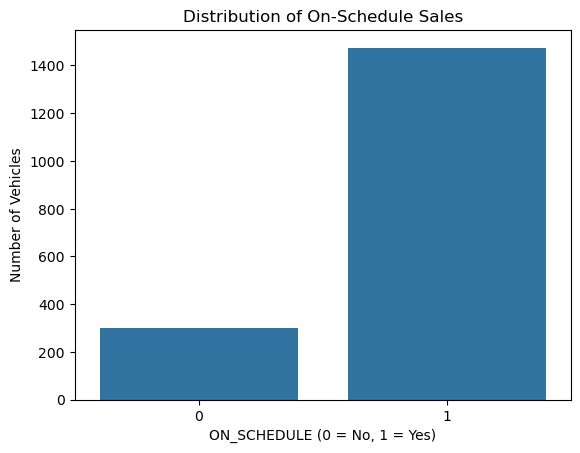

In [6]:
sns.countplot(data=df_model, x="ON_SCHEDULE")
plt.title("Distribution of On-Schedule Sales")
plt.xlabel("ON_SCHEDULE (0 = No, 1 = Yes)")
plt.ylabel("Number of Vehicles")
plt.show()

The target distribution should be checked before model training. If one class is much more common than the other, accuracy alone may be misleading; precision, recall, F1-score, and the confusion matrix should also be considered.

### 2.2 Defining Predictors and Target

`SELLING_PRICE`, `LISTING_DAYS`, and `SALE_DEADLINE` are excluded because they are used to create the target or reveal the sale outcome. `MODEL` is also excluded to reduce the effect of a categorical feature with many unique values. Missing predictor values will be imputed inside the model pipeline, fitted using training data only.

In [7]:
columns_to_drop = [
    "ON_SCHEDULE",
    "SALE_DEADLINE",
    "SELLING_PRICE",
    "LISTING_DAYS",
    "MODEL"
]

X = df_model.drop(columns=columns_to_drop)
y = df_model["ON_SCHEDULE"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("\nPredictor columns:")
print(X.columns.tolist())


Predictor shape: (1776, 15)
Target shape: (1776,)

Predictor columns:
['MAKE', 'YEAR', 'KILOMETRES', 'ENGINE_SIZE', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE', 'DRIVETRAIN', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'COLOUR', 'HAS_WARRANTY', 'CONDITION_SCORE']


## 3.Model Development and Evaluation

### 3.1 Train-Test Split

The dataset is divided into training and testing sets, with 80% of the data used for training and 20% reserved for testing. Stratified splitting was used to maintain the proportion of vehicles sold on schedule and those not sold on schedule in both sets. 

In [8]:
from sklearn.model_selection import train_test_split

# Split the predictors and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y
)

# Display the shapes of the resulting datasets
print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training predictors: (1420, 15)
Testing predictors: (356, 15)
Training target: (1420,)
Testing target: (356,)


### 3.2 Feature Preprocessing

The predictor variables contain both numerical and categorical data, with some missing values. A preprocessing pipeline is used to impute missing values, scale numerical features, and encode categorical features. Missing numerical values were handled using median imputation, while missing categorical values were filled using the most frequent category. Numerical features were standardized, and categorical features were one-hot encoded using a preprocessing pipeline fitted on the training data. The preprocessing steps are fitted on the training data to prevent information from the test set influencing model training.

In [21]:
# Identify numerical and categorical predictor columns
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)
print("\nNumber of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

Numerical columns: ['YEAR', 'KILOMETRES', 'ENGINE_SIZE', 'DOORS', 'SEATS', 'ACCIDENTS', 'OWNERS', 'HAS_WARRANTY', 'CONDITION_SCORE']

Categorical columns: ['MAKE', 'FUEL_TYPE', 'TRANSMISSION', 'BODY_TYPE', 'DRIVETRAIN', 'COLOUR']

Number of numerical columns: 9
Number of categorical columns: 6


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

### 3.3 Model Training 

#### Logistic regression 

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### Decision Tree

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier())
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


### Support Vector Machine 

In [13]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

svm_model.fit(X_train, y_train)

print("Support Vector Machine training completed.")

Support Vector Machine training completed.


### 3.4 Model Evaluation

The three trained classifiers are evaluated using the test dataset. Accuracy, precision, recall, and F1-score are used to compare their classification performance. Confusion matrices were also examined to understand correct and incorrect predictions. Because the target classes are imbalanced, performance across both classes is considered when comparing the models.

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Support Vector Machine": svm_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.828652,0.834758,0.989865,0.905719
1,Decision Tree,0.713483,0.846429,0.800676,0.822917
2,Support Vector Machine,0.831461,0.831461,1.000000,0.907975


In [15]:
for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name}")
    print("Predicted class counts:")
    print(pd.Series(y_pred).value_counts().sort_index())


Logistic Regression
Predicted class counts:
0      5
1    351
Name: count, dtype: int64

Decision Tree
Predicted class counts:
0     76
1    280
Name: count, dtype: int64

Support Vector Machine
Predicted class counts:
1    356
Name: count, dtype: int64


**Addressing Class Imbalance**

The initial Logistic Regression and SVM models tended to predict vehicles as on schedule. To address this, balanced versions of both models are tested using `class_weight='balanced'`. This gives greater weight to the underrepresented class and helps assess whether the models can better identify vehicles that did not sell on schedule.

In [16]:
logistic_balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

logistic_balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression training completed.")

Balanced Logistic Regression training completed.


In [18]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(class_weight="balanced"))
])

svm_balanced_model.fit(X_train, y_train)

print("Balanced SVM training completed.")

Balanced SVM training completed.


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_to_compare = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "SVM": svm_model,
    "Balanced Logistic Regression": logistic_balanced_model,
    "Balanced SVM": svm_balanced_model
}

comparison = []

for name, model in models_to_compare.items():
    y_pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall - Not on schedule": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Recall - On schedule": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
comparison_df.round(3)

,Model,Accuracy,F1,Recall - Not on schedule,Recall - On schedule
0,Logistic Regression,0.829,0.484,0.033,0.990
1,Decision Tree,0.713,0.536,0.283,0.801
2,SVM,0.831,0.454,0.000,1.000
3,Balanced Logistic Regression,0.587,0.513,0.583,0.588
4,Balanced SVM,0.629,0.506,0.383,0.679


## 4. Evaluation and Selection

The models were evaluated using accuracy, F1-score, and recall for each class. Since the target variable is imbalanced, accuracy alone was not sufficient to assess model performance. Therefore, the evaluation considered how well each model identified both on-schedule and not-on-schedule vehicles.

### 4.1 Assessing Model performance 

In [20]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)
import pandas as pd

final_models = {
    "Balanced Logistic Regression": logistic_balanced_model,
    "Decision Tree": decision_tree_model,
    "Balanced SVM": svm_balanced_model
}

final_results = []

for name, model in final_models.items():
    predictions = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall - Not on schedule": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Recall - On schedule": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

final_results_df = pd.DataFrame(final_results)
final_results_df.round(3)

,Model,Accuracy,F1,Recall - Not on schedule,Recall - On schedule
0,Balanced Logistic Regression,0.587,0.513,0.583,0.588
1,Decision Tree,0.713,0.536,0.283,0.801
2,Balanced SVM,0.629,0.506,0.383,0.679


### 4.2 Best Model Selection

The Decision Tree provided the best overall performance based on accuracy and F1-score. However, Balanced Logistic Regression was better at identifying vehicles that did not sell on schedule. This comparison showed that accuracy alone is insufficient for imbalanced datasets. Model performance may also vary with different train-test splits, and the best model depends on the project's objective.

### 4.3 Reflection on Model Performance

The results showed that the best model depends on the evaluation metric and the project's objective. Although the Decision Tree achieved the highest accuracy and F1-score among the three final models, Balanced Logistic Regression identified more vehicles that did not sell on schedule. This highlights the importance of considering multiple evaluation metrics when working with an imbalanced dataset.